In [2]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn tensorflow joblib

In [3]:
import os
import json
import random
import time
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    SpatialDropout1D,
)
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_PATH = "dataset.csv"
OUTPUT_DIR = Path("results")
MODEL_DIR = Path("models")

OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
df = pd.read_csv(DATA_PATH)

required_columns = ["review_text", "sentiment"]
missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {missing_columns}"
    )

df = df.dropna(subset=required_columns).copy()
df["review_text"] = df["review_text"].astype(str).str.strip()
df["sentiment"] = df["sentiment"].astype(str).str.lower().str.strip()

df = df[df["review_text"].ne("")].copy()

valid_labels = {"negatif", "netral", "positif"}
df = df[df["sentiment"].isin(valid_labels)].copy()

df = df.drop_duplicates(subset=["review_text"]).reset_index(drop=True)

print("Jumlah sampel valid:", len(df))
print("\nDistribusi kelas:")
print(df["sentiment"].value_counts())

display(df[["review_text", "sentiment"]].head())

Jumlah sampel valid: 12756

Distribusi kelas:
sentiment
positif    6862
netral     3172
negatif    2722
Name: count, dtype: int64


,review_text,sentiment
0,fun,positif
1,gud,netral
2,Fun and Chill game that you can play when you ...,positif
3,i've spent so many hours avoiding deadlines on...,negatif
4,its gooooooood,netral


In [5]:
X = df["review_text"].to_numpy()
y_text = df["sentiment"].to_numpy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

print("Mapping kelas:")
for i, label in enumerate(label_encoder.classes_):
    print(i, "=", label)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

print("\nJumlah training:", len(X_train))
print("Jumlah testing:", len(X_test))

print("\nDistribusi training:")
print(pd.Series(
    label_encoder.inverse_transform(y_train)
).value_counts())

print("\nDistribusi testing:")
print(pd.Series(
    label_encoder.inverse_transform(y_test)
).value_counts())

Mapping kelas:
0 = negatif
1 = netral
2 = positif

Jumlah training: 10204
Jumlah testing: 2552

Distribusi training:
positif    5489
netral     2537
negatif    2178
Name: count, dtype: int64

Distribusi testing:
positif    1373
netral      635
negatif     544
Name: count, dtype: int64


In [6]:
experiment_results = []

def evaluate_model(name, model, Xtr, Xte, ytr, yte):
    start = time.time()
    model.fit(Xtr, ytr)
    train_seconds = time.time() - start

    pred_train = model.predict(Xtr)
    pred_test = model.predict(Xte)

    train_acc = accuracy_score(ytr, pred_train)
    test_acc = accuracy_score(yte, pred_test)

    macro_f1 = f1_score(
        yte, pred_test, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        yte, pred_test, average="weighted", zero_division=0
    )

    result = {
        "experiment": name,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc,
        "test_macro_f1": macro_f1,
        "test_weighted_f1": weighted_f1,
        "training_seconds": train_seconds,
    }

    experiment_results.append(result)

    print(f"\n===== {name} =====")
    print(f"Training accuracy: {train_acc:.4f}")
    print(f"Testing accuracy : {test_acc:.4f}")
    print(f"Macro F1         : {macro_f1:.4f}")
    print(f"Waktu training   : {train_seconds:.2f} detik")

    print("\nClassification report:")
    print(
        classification_report(
            yte,
            pred_test,
            labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            zero_division=0,
        )
    )

    cm = confusion_matrix(
        yte,
        pred_test,
        labels=np.arange(len(label_encoder.classes_)),
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Prediksi")
    plt.ylabel("Label sebenarnya")
    plt.tight_layout()
    plt.show()

    return result


In [7]:
tfidf_lr = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    max_features=30000,
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
)

X_train_tfidf = tfidf_lr.fit_transform(X_train)
X_test_tfidf = tfidf_lr.transform(X_test)

print("Dimensi fitur training:", X_train_tfidf.shape)
print("Dimensi fitur testing :", X_test_tfidf.shape)
print("Contoh fitur:", tfidf_lr.get_feature_names_out()[:20])


Dimensi fitur training: (10204, 23530)
Dimensi fitur testing : (2552, 23530)
Contoh fitur: ['00' '00 am' '00 pm' '000' '000 hours' '10' '10 10' '10 20'
 '10 absolutely' '10 also' '10 and' '10 anos' '10 author' '10 best'
 '10 but' '10 can' '10 cant' '10 cozy' '10 days' '10 experience']



===== TF-IDF + Logistic Regression =====
Training accuracy: 0.9713
Testing accuracy : 0.8625
Macro F1         : 0.8405
Waktu training   : 8.62 detik

Classification report:
              precision    recall  f1-score   support

     negatif       0.76      0.77      0.77       544
      netral       0.80      0.89      0.84       635
     positif       0.94      0.89      0.91      1373

    accuracy                           0.86      2552
   macro avg       0.83      0.85      0.84      2552
weighted avg       0.87      0.86      0.86      2552



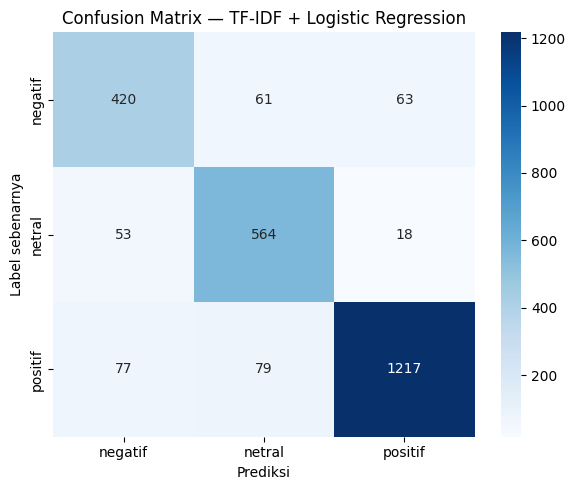

In [8]:
model_lr = LogisticRegression(
    C=3.0,
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED,
)

result_lr = evaluate_model(
    "TF-IDF + Logistic Regression",
    model_lr,
    X_train_tfidf,
    X_test_tfidf,
    y_train,
    y_test,
)


In [9]:
import joblib

joblib.dump(
    {
        "vectorizer": tfidf_lr,
        "model": model_lr,
        "label_encoder": label_encoder,
    },
    MODEL_DIR / "tfidf_logistic_regression.joblib",
)

print("Model baseline berhasil disimpan.")

Model baseline berhasil disimpan.


Iteration 1, loss = 0.84172327
Validation score: 0.769833
Iteration 2, loss = 0.34215210
Validation score: 0.836435
Iteration 3, loss = 0.11512368
Validation score: 0.837414
Iteration 4, loss = 0.05806580
Validation score: 0.835455
Iteration 5, loss = 0.04205098
Validation score: 0.826641
Iteration 6, loss = 0.03552841
Validation score: 0.830558
Iteration 7, loss = 0.03271615
Validation score: 0.828599
Iteration 8, loss = 0.03174370
Validation score: 0.827620
Validation score did not improve more than tol=0.000100 for 4 consecutive epochs. Stopping.

===== TF-IDF + MLP Neural Network =====
Training accuracy: 0.9734
Testing accuracy : 0.8425
Macro F1         : 0.8150
Waktu training   : 44.06 detik

Classification report:
              precision    recall  f1-score   support

     negatif       0.76      0.69      0.72       544
      netral       0.83      0.83      0.83       635
     positif       0.88      0.91      0.89      1373

    accuracy                           0.84      255

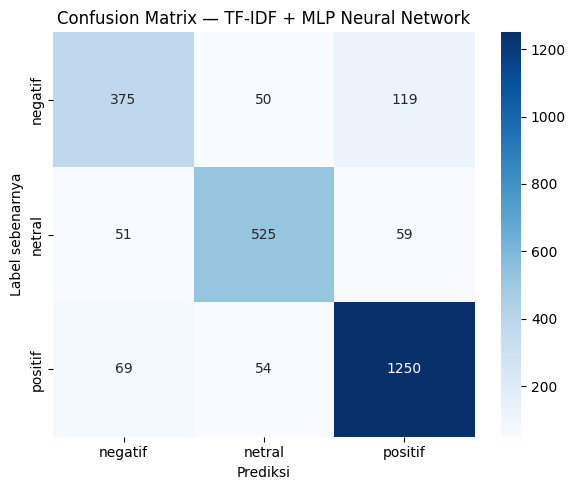

In [10]:
model_mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=128,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=4,
    random_state=SEED,
    verbose=True,
)

result_mlp = evaluate_model(
    "TF-IDF + MLP Neural Network",
    model_mlp,
    X_train_tfidf,
    X_test_tfidf,
    y_train,
    y_test,
)

In [11]:
joblib.dump(
    {
        "vectorizer": tfidf_lr,
        "model": model_mlp,
        "label_encoder": label_encoder,
    },
    MODEL_DIR / "tfidf_mlp.joblib",
)

print("Model MLP berhasil disimpan.")

Model MLP berhasil disimpan.


In [12]:
MAX_WORDS = 30000
MAX_LEN = 200

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>",
    lower=True,
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
)

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1,
)

print("Ukuran kosakata:", vocab_size)
print("Dimensi training:", X_train_pad.shape)
print("Dimensi testing :", X_test_pad.shape)

Ukuran kosakata: 13818
Dimensi training: (10204, 200)
Dimensi testing : (2552, 200)


In [13]:
num_classes = len(label_encoder.classes_)

model_bilstm = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=False,
    ),
    SpatialDropout1D(0.2),
    Bidirectional(
        LSTM(64, return_sequences=False)
    ),
    Dropout(0.4),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax"),
])

model_bilstm.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_bilstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

start_time = time.time()

history = model_bilstm.fit(
    X_train_pad,
    y_train,
    validation_split=0.1,
    epochs=12,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1,
)

bilstm_training_seconds = time.time() - start_time

print(
    f"Waktu training BiLSTM: "
    f"{bilstm_training_seconds:.2f} detik"
)

Epoch 1/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.6541 - loss: 0.7819 - val_accuracy: 0.7620 - val_loss: 0.5778
Epoch 2/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8459 - loss: 0.4139 - val_accuracy: 0.8257 - val_loss: 0.4344
Epoch 3/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9309 - loss: 0.2184 - val_accuracy: 0.8394 - val_loss: 0.4709
Epoch 4/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9574 - loss: 0.1440 - val_accuracy: 0.8501 - val_loss: 0.4962
Epoch 5/12
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9710 - loss: 0.1066 - val_accuracy: 0.8404 - val_loss: 0.5454
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Waktu training BiLSTM: 21.03 detik


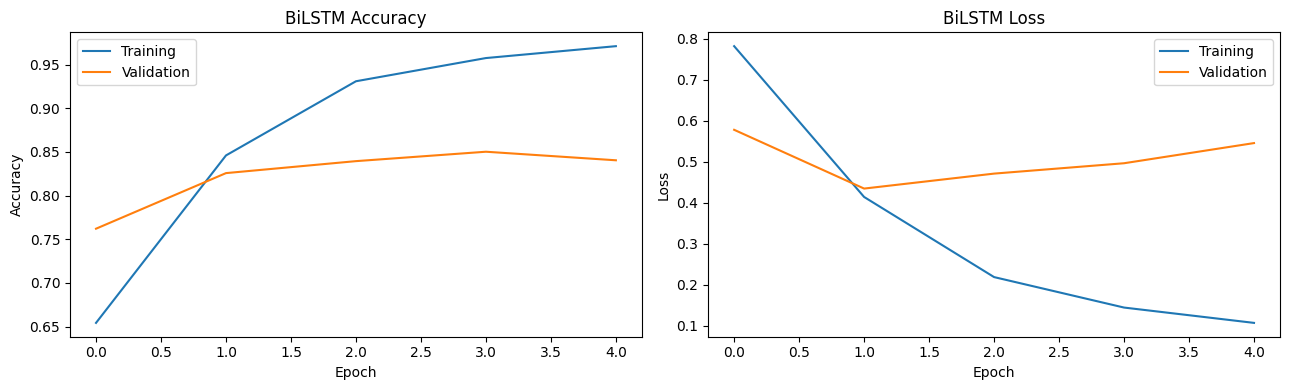

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("BiLSTM Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("BiLSTM Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "bilstm_training_history.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

Training accuracy: 0.9206
Testing accuracy : 0.8421
Macro F1         : 0.8182

Classification report:
              precision    recall  f1-score   support

     negatif       0.65      0.80      0.72       544
      netral       0.86      0.81      0.83       635
     positif       0.93      0.87      0.90      1373

    accuracy                           0.84      2552
   macro avg       0.81      0.83      0.82      2552
weighted avg       0.85      0.84      0.85      2552



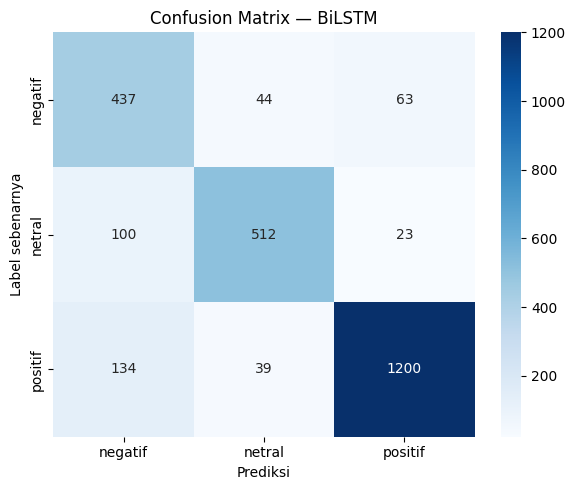

In [16]:
start_time = time.time()

train_prob = model_bilstm.predict(
    X_train_pad, batch_size=256, verbose=0
)
test_prob = model_bilstm.predict(
    X_test_pad, batch_size=256, verbose=0
)

pred_train_bilstm = np.argmax(train_prob, axis=1)
pred_test_bilstm = np.argmax(test_prob, axis=1)

prediction_seconds = time.time() - start_time

train_acc_bilstm = accuracy_score(
    y_train, pred_train_bilstm
)
test_acc_bilstm = accuracy_score(
    y_test, pred_test_bilstm
)

macro_f1_bilstm = f1_score(
    y_test,
    pred_test_bilstm,
    average="macro",
    zero_division=0,
)

weighted_f1_bilstm = f1_score(
    y_test,
    pred_test_bilstm,
    average="weighted",
    zero_division=0,
)

result_bilstm = {
    "experiment": "Embedding + BiLSTM",
    "train_accuracy": train_acc_bilstm,
    "test_accuracy": test_acc_bilstm,
    "test_macro_f1": macro_f1_bilstm,
    "test_weighted_f1": weighted_f1_bilstm,
    "training_seconds": bilstm_training_seconds,
}

experiment_results.append(result_bilstm)

print(f"Training accuracy: {train_acc_bilstm:.4f}")
print(f"Testing accuracy : {test_acc_bilstm:.4f}")
print(f"Macro F1         : {macro_f1_bilstm:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        pred_test_bilstm,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0,
    )
)

cm = confusion_matrix(
    y_test,
    pred_test_bilstm,
    labels=np.arange(num_classes),
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title("Confusion Matrix — BiLSTM")
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrix_bilstm.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [17]:
model_bilstm.save(MODEL_DIR / "sentiment_bilstm.keras")

with open(MODEL_DIR / "tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open(MODEL_DIR / "label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

with open(MODEL_DIR / "model_config.json", "w") as f:
    json.dump(
        {
            "max_words": MAX_WORDS,
            "max_len": MAX_LEN,
            "num_classes": num_classes,
            "class_names": label_encoder.classes_.tolist(),
            "seed": SEED,
        },
        f,
        indent=2,
    )

print("Model dan artefak BiLSTM berhasil disimpan.")

Model dan artefak BiLSTM berhasil disimpan.


In [18]:
results_df = pd.DataFrame(experiment_results)

results_df = results_df.sort_values(
    by="test_macro_f1",
    ascending=False,
).reset_index(drop=True)

results_df.to_csv(
    OUTPUT_DIR / "experiment_results.csv",
    index=False,
)

display(
    results_df.style.format({
        "train_accuracy": "{:.2%}",
        "test_accuracy": "{:.2%}",
        "test_macro_f1": "{:.2%}",
        "test_weighted_f1": "{:.2%}",
        "training_seconds": "{:.2f}",
    })
)

print("\nModel dengan macro F1 tertinggi:")
print(results_df.iloc[0]["experiment"])

,experiment,train_accuracy,test_accuracy,test_macro_f1,test_weighted_f1,training_seconds
0,TF-IDF + Logistic Regression,97.13%,86.25%,84.05%,86.36%,8.62
1,Embedding + BiLSTM,92.06%,84.21%,81.82%,84.61%,21.03
2,TF-IDF + MLP Neural Network,97.34%,84.25%,81.50%,84.08%,44.06



Model dengan macro F1 tertinggi:
TF-IDF + Logistic Regression


In [20]:
def predict_sentiment(text):
    sequence = tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post",
    )

    probabilities = model_bilstm.predict(
        padded, verbose=0
    )[0]

    predicted_id = int(np.argmax(probabilities))
    predicted_label = label_encoder.inverse_transform(
        [predicted_id]
    )[0]

    confidence = float(probabilities[predicted_id])

    return {
        "review": text,
        "sentiment": predicted_label,
        "confidence": round(confidence, 4),
    }


test_reviews = [
    "This game is relaxing and incredibly fun!",
    "The gameplay is frustrating and boring.",
    "The game has farming and fishing.",
]

for review in test_reviews:
    print(predict_sentiment(review))

{'review': 'This game is relaxing and incredibly fun!', 'sentiment': 'positif', 'confidence': 0.9981}
{'review': 'The gameplay is frustrating and boring.', 'sentiment': 'negatif', 'confidence': 0.9159}
{'review': 'The game has farming and fishing.', 'sentiment': 'netral', 'confidence': 0.5041}


In [27]:
import zipfile
from pathlib import Path

zip_filename = 'outputs.zip'
folders_to_zip = ['results', 'models']

with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for folder_name in folders_to_zip:
        folder_path = Path(folder_name)
        if folder_path.exists():
            for file_path in folder_path.rglob('*'):
                if file_path.is_file():
                    # Gunakan write() dengan parameter arcname agar struktur folder tetap terjaga di dalam zip
                    zipf.write(file_path, arcname=file_path.relative_to(folder_path.parent))
            print(f"Folder '{folder_name}' berhasil ditambahkan ke zip.")
        else:
            print(f"Folder '{folder_name}' tidak ditemukan.")



Folder 'results' berhasil ditambahkan ke zip.
Folder 'models' berhasil ditambahkan ke zip.
